# Imports

In [1]:
# stop - UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
import os
os.environ["OMP_NUM_THREADS"] = "1"


from utils import *



import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

# from scipy.stats import norm

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Setup

In [2]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# output path for choosing clusters
cluster_output_path = [f"../results/kmeans_clusters_{zone}.png" for zone in structural_zones]

# type of grouping
group_type = 'dbscan'

# output path for interpretation
output_dir = r'../results'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.683097,...,0.034439,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0
1,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
2,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
3,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
4,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1


# DBSCAN

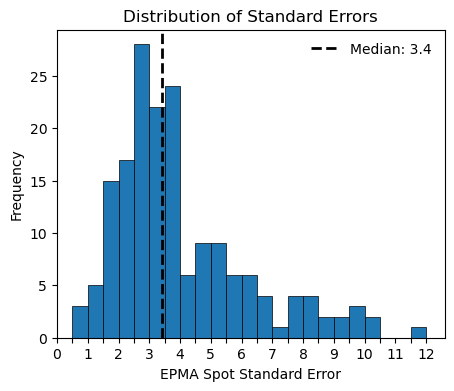

In [3]:
fig, ax = plt.subplots(figsize=(5,4))

bins = np.arange(0, df['error'].max()+0.5, 0.5)
ax.hist(x=df['error'], linewidth=0.5, edgecolor='k', facecolor='tab:blue', bins=bins, align='mid')
ax.axvline(x=df['error'].median(), color='k', linestyle='--', linewidth=2, label=f"Median: {round(df['error'].median(), 1)}")

ax.legend(frameon=False)
ax.set_xlim(0)
ax.set_xticks(bins)
ax.set_xticklabels([int(i) if i%1==0 else '' for i in bins])
ax.set_title('Distribution of Standard Errors')
ax.set_ylabel('Frequency')
ax.set_xlabel('EPMA Spot Standard Error')

plt.show()

In [12]:

def dbscan_processing(df, eps, min_samples):
    ages = df['age'].to_numpy().reshape(-1, 1)

    dbs = DBSCAN(eps=eps, min_samples=min_samples).fit(ages)
    df = df.copy()  # avoid mutating caller's df
    df['labels'] = dbs.labels_

    # 1) Mean age per *cluster* (exclude noise = -1)
    means = (df.loc[df['labels'] != -1].groupby('labels')['age'].mean().sort_values())

    # 3) Build mapping old -> new (0..K-1) in ascending mean age
    remap = {old_label: new_idx for new_idx, old_label in enumerate(means.index)}
    K = len(remap)

    # Apply mapping; keep noise as -1
    df['labels'] = df['labels'].map(remap).fillna(-1).astype(int)

    # (Optional) group mean (after relabel) if you still want it
    # df['mean age'] = df.groupby('labels')['age'].transform('mean')

    # 4) Sort with noise (-1) last, then by error (or age if you prefer)
    sort_key = np.where(df['labels'] == -1, K, df['labels'])
    df = df.iloc[np.lexsort((df.get('error', 0), sort_key))].reset_index(drop=True)

    df = df.sort_values(['labels', 'error'])

    return df


In [13]:
test = dbscan_processing(df.loc[df['zone']=='CMZI'].copy(), 1.5, 3)

test

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite,labels
48,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.240000,1.408622,...,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1,-1
49,7,17,EB14-002,CMZI,m19,rim,Y enriched rim,5.0,327.560000,1.487717,...,0.073522,0.009689,0.010192,0.082282,0.454182,59.344706,2.079801,1,0,-1
50,21,27,WA14-002,CMZI,m13,core,Y enriched core,5.0,386.400000,1.944418,...,0.041634,0.009539,0.011515,0.082172,0.503214,60.254373,1.715951,1,1,-1
51,30,158,WA15-4,CMZI,m3,core,Y depleted core,NaN,388.000000,2.194640,...,0.022901,0.018130,0.016221,0.083969,0.565629,56.905109,2.803414,0,1,-1
52,50,151,WA15-4,CMZI,m1,core,Y depeted core,NaN,390.000000,2.646004,...,0.038745,0.026460,0.015120,0.085995,0.678463,56.894754,2.739559,0,1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43,73,162,WA15-4,CMZI,m6,core,Y depleted core,NaN,378.000000,3.105940,...,0.040471,0.074354,0.016941,0.082825,0.821677,54.732316,3.201942,0,1,8
44,48,3,EB14-001,CMZI,m24,core,Y enriched core,6.0,382.733333,2.654400,...,0.088974,0.009531,0.009531,0.079471,0.693538,55.843337,2.927733,1,0,9
45,121,154,WA15-4,CMZI,m14,core,Y depleted core,NaN,382.000000,4.539991,...,0.034282,0.084314,0.019457,0.082461,1.188479,54.094459,3.051059,0,1,9
46,154,12,EB14-002,CMZI,m12,core,Y enriched core,5.0,382.940000,7.268492,...,0.008926,0.008926,0.017534,0.096464,1.898076,53.428406,1.822265,1,0,9


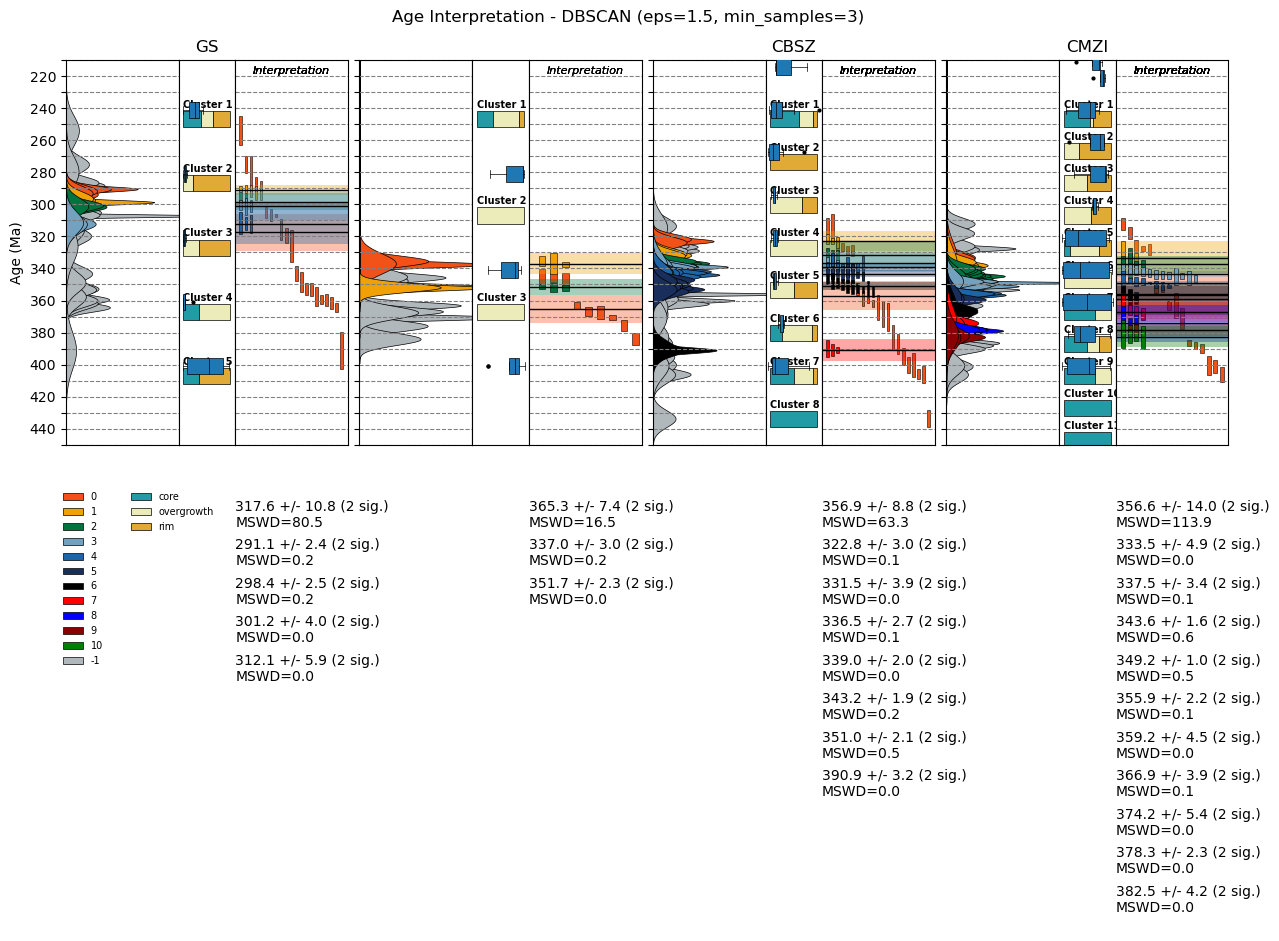

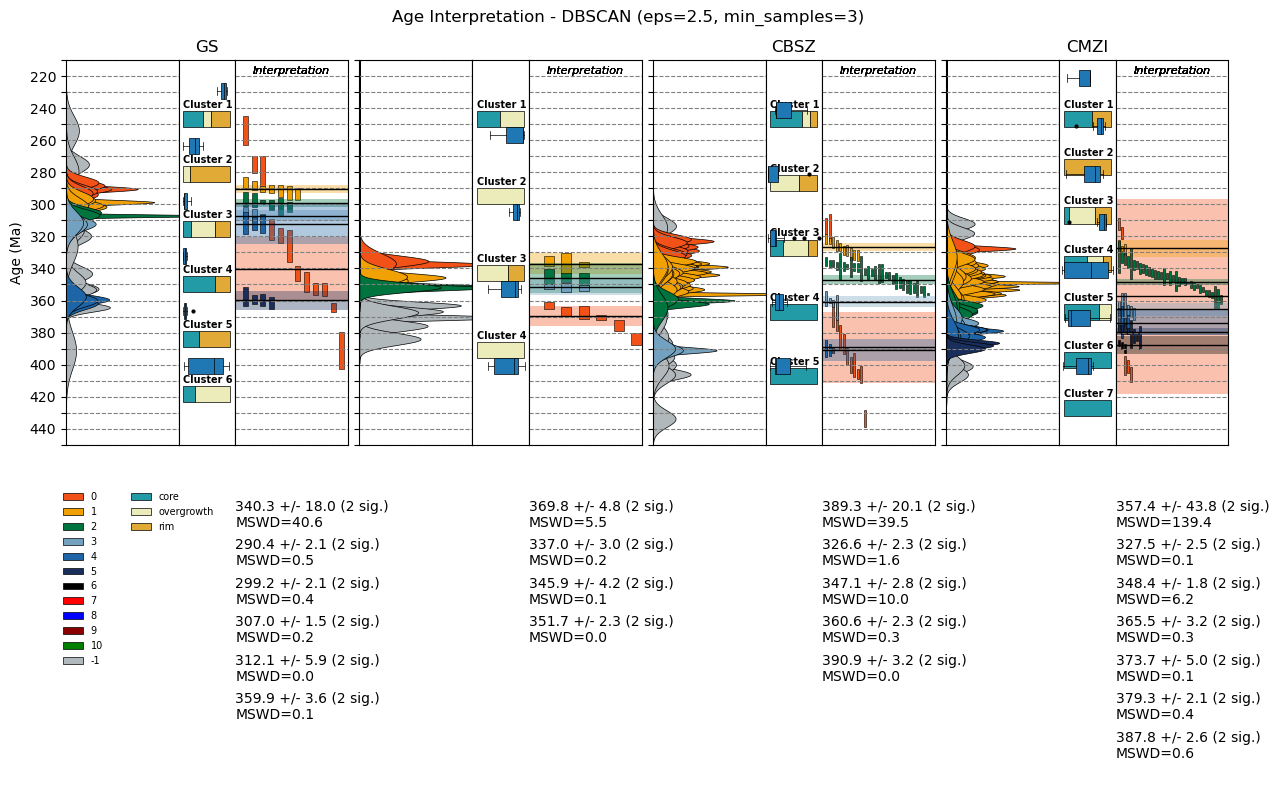

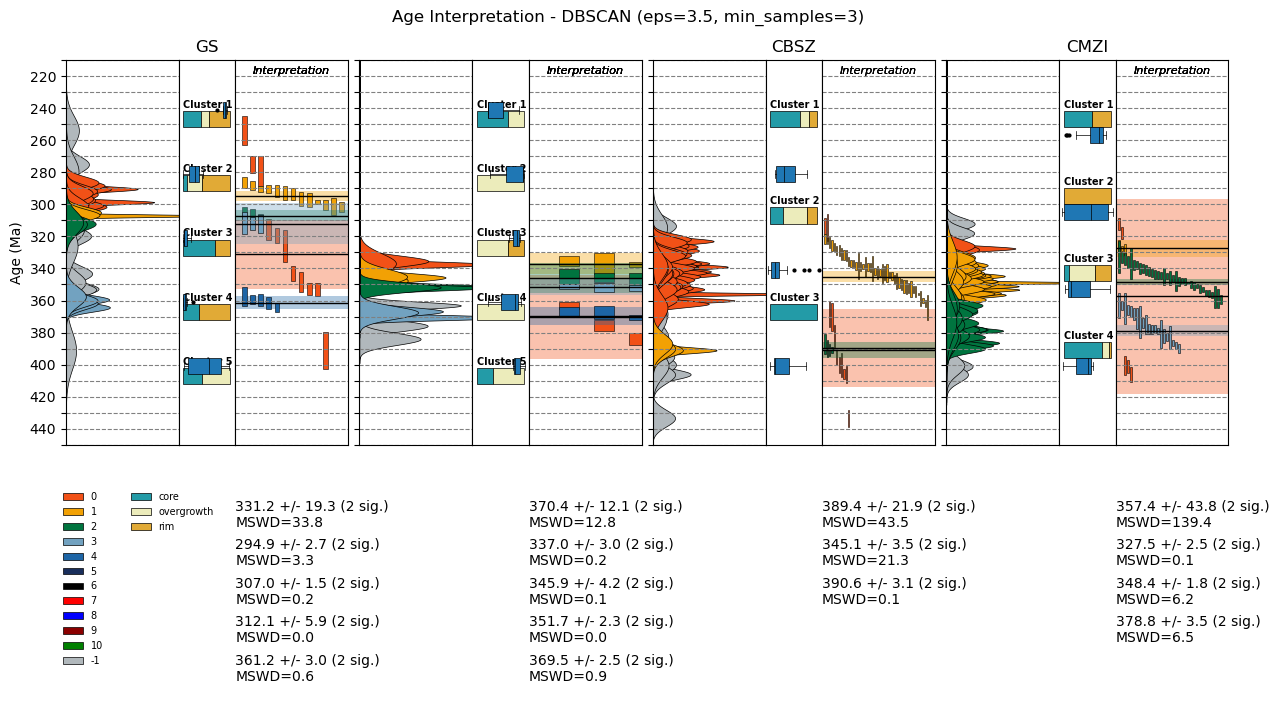

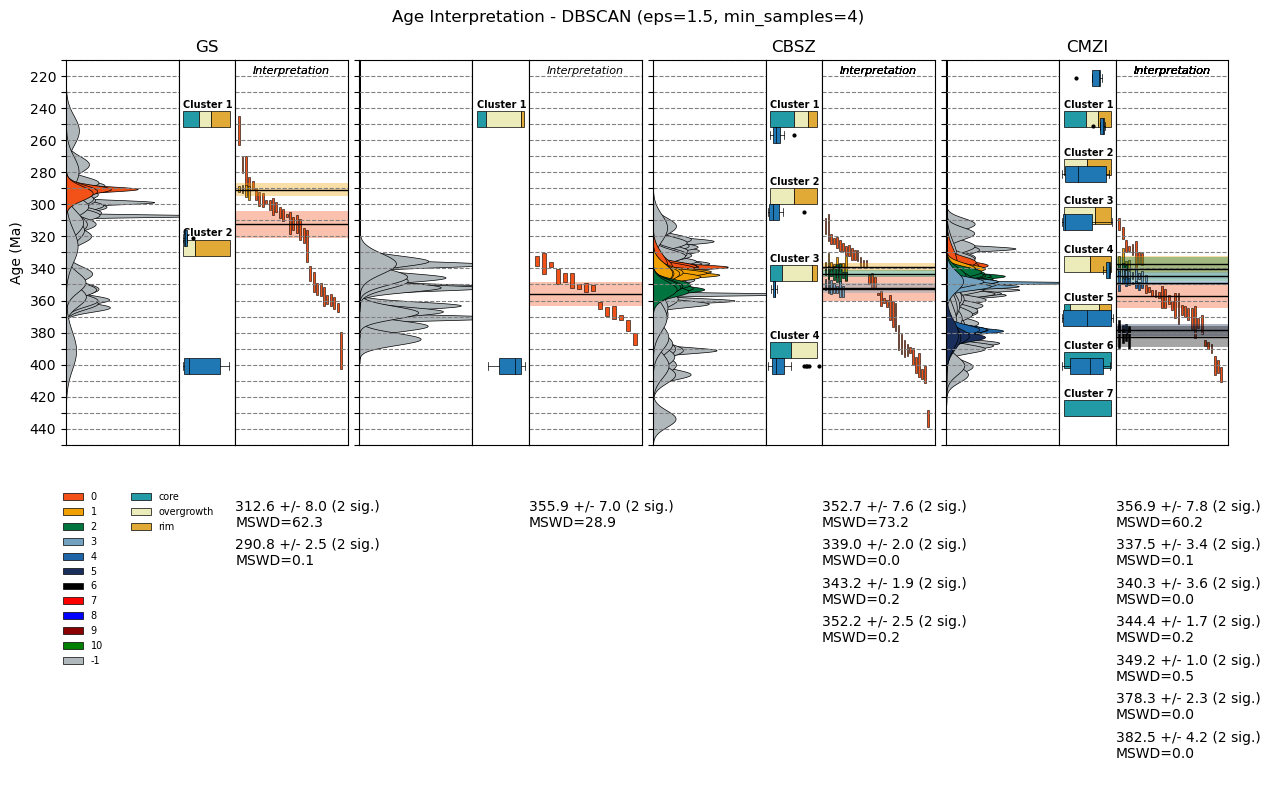

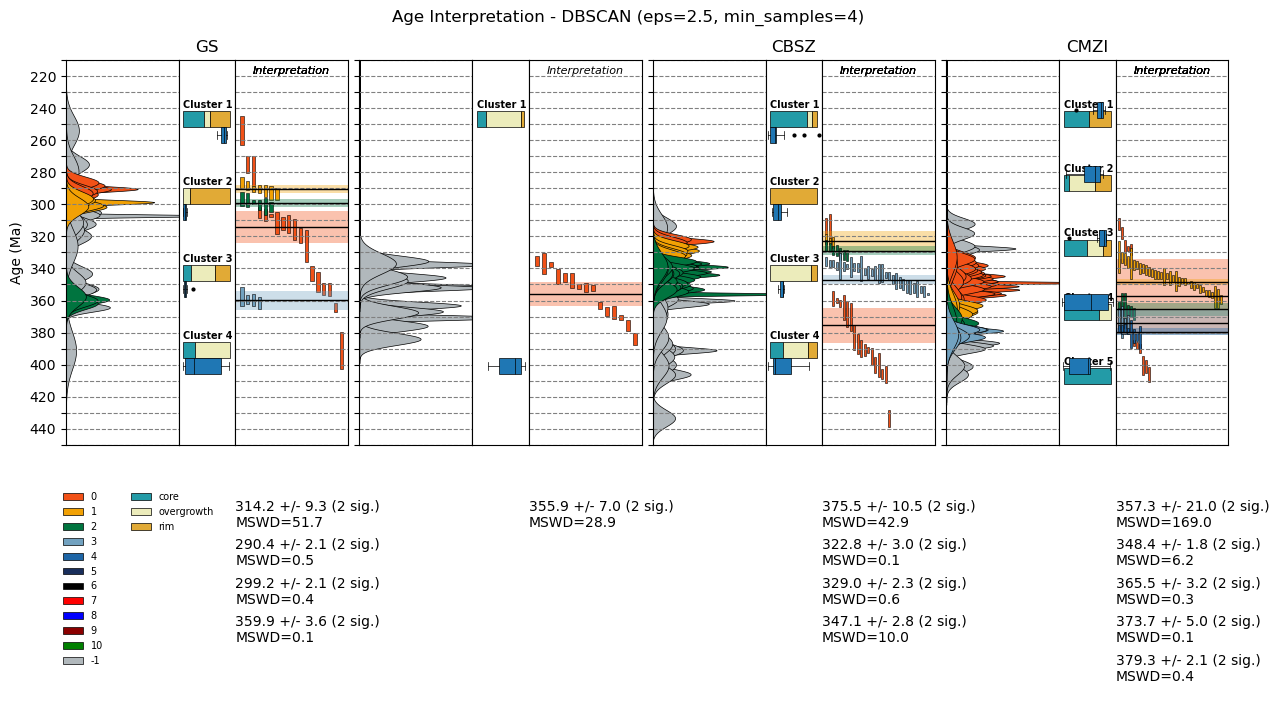

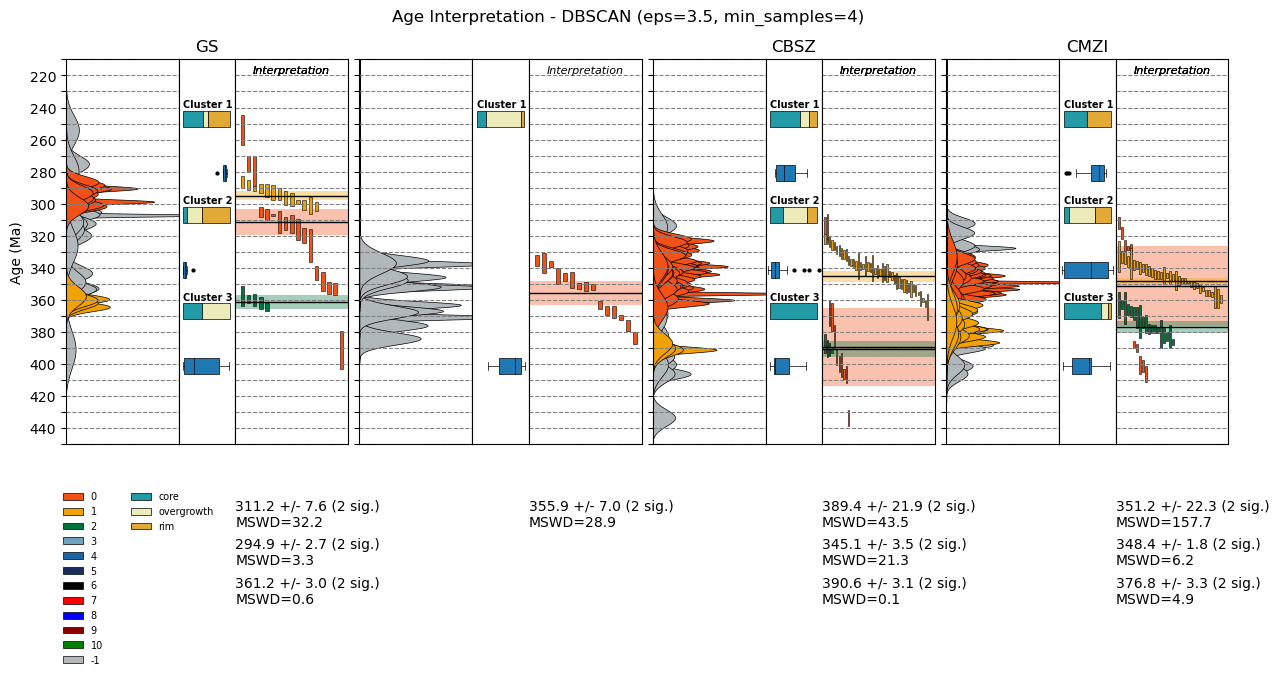

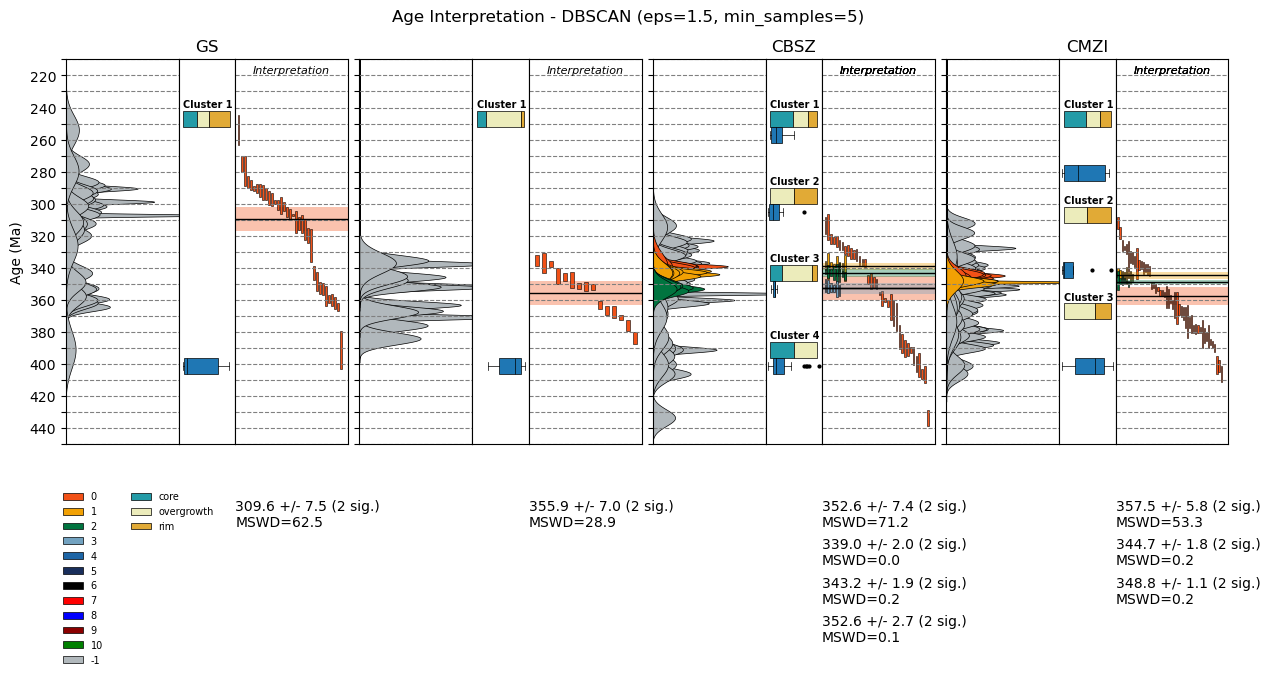

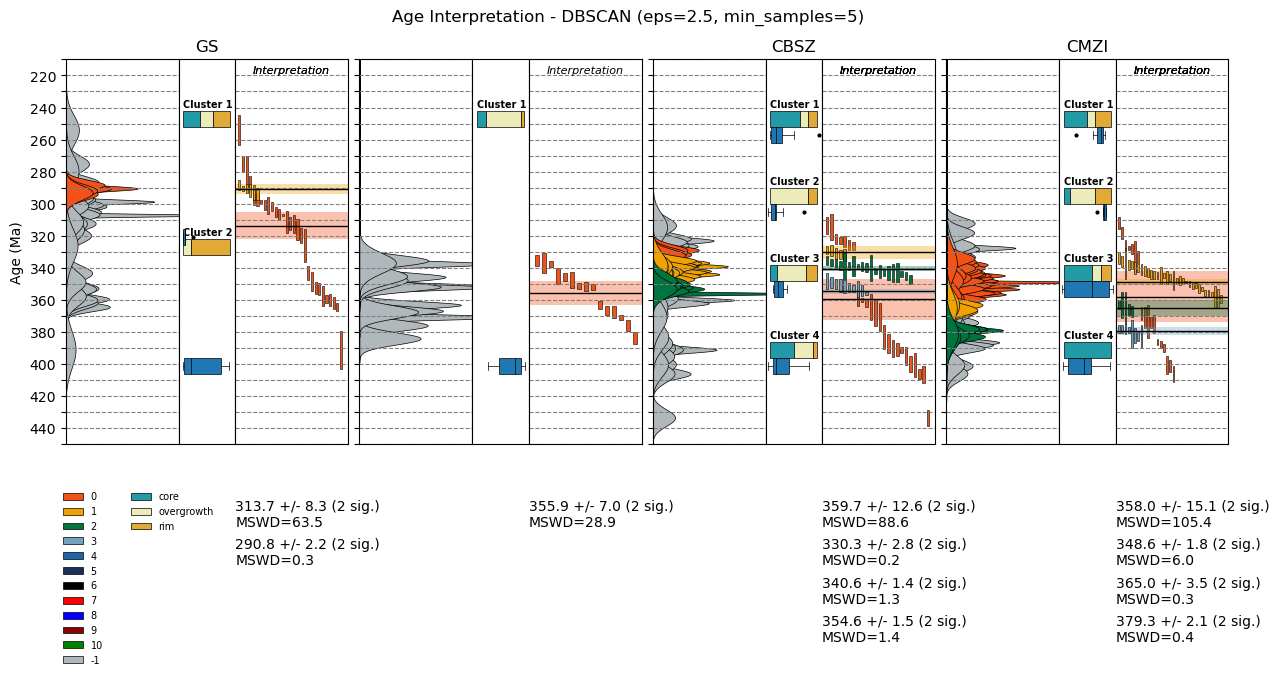

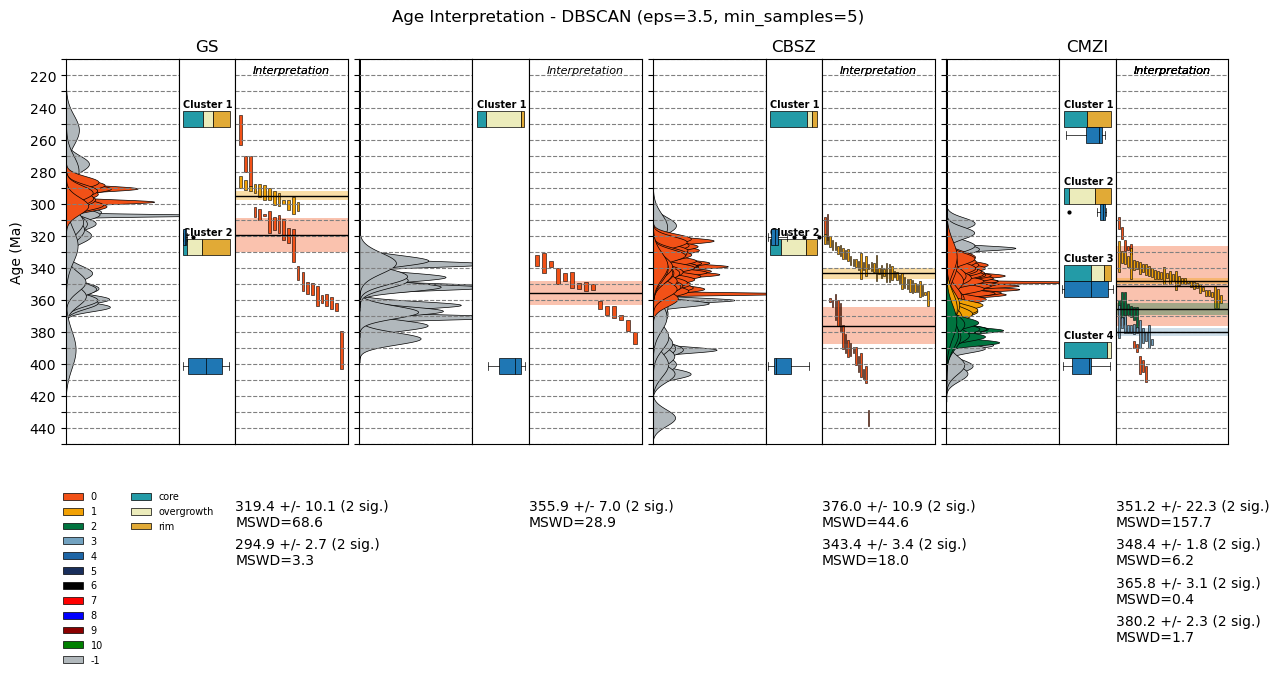

In [16]:


min_samples = [3, 4, 5]

eps = [1.5, 2.5, 3.5]



for ms in min_samples:
    for e in eps:


        fig = plt.figure(figsize=(15, 5))
        width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
        gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)


        axA_1 = fig.add_subplot(gs[0, 0])
        axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
        axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
        ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
        axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
        axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
        axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
        ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
        axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
        axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
        axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
        ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
        axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
        axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
        axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)


        ax_sp1.axis("off")
        ax_sp2.axis("off")
        ax_sp3.axis("off")


        axA_1.set_ylim(450, 210)


        panel1_max = [0.0, 0.0, 0.0, 0.0]
        panel3_max = [0.0, 0.0, 0.0, 0.0]


        # iterate through structural zones...
        for idx, zone in enumerate(structural_zones):

            df_subset = df.loc[df['zone']==zone].copy()

            df_dbscan = dbscan_processing(df_subset, e, ms)

            num_components = len(df_dbscan['labels'].unique())
            component_labels = df_dbscan['labels'].unique()
            y_max = df_dbscan['Y2O3'].max()


            # iterate through each cluster label...
            for k, component in enumerate(component_labels):

                df_dbscan_subset = df_dbscan.loc[df_dbscan['labels'] == component].copy()
                spacing = (450-210) / (num_components + 1)
                center = 240 + (k * spacing)

                # df_dbscan_subset = df_dbscan_subset.loc[df_dbscan_subset['labels']!=-1]

                # MDHSZ...
                if idx==0:
                    sample_max = plot_samples_panel(df_dbscan_subset, axA_1, 'labels', age_group_colors, label_bool=True, timeline=[210, 450], ylabel='Age (Ma)')

                    # axA_1B = axA_1.twiny()
                    # plot_components_panel(axA_1B, comp, time, mix, age_group_colors)


                    plot_ageinterp_panel(df_dbscan_subset, axA_3, k, age_group_colors, bar_width, gap)

                    texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                    texture_counts = dict(sorted(texture_counts.items()))
                    horizontal_stack(axA_2, f"Cluster {k+1}", center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy(), y_max)
                    
                    axA_2.set_title(zone, loc='center')

                    # plot age group information below plot...
                    ages = df_dbscan_subset['age'].to_numpy()
                    errors = df_dbscan_subset['error'].to_numpy()
                    stats = cluster_stats(ages, errors, two_sigma=True)
                    label = f"\n{round(stats['mean'],1)} +/- {round(stats['ci95_halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    axA_3.text(0, -0.1-(k/10), label, transform=axA_3.transAxes, fontsize=10, ha='left', va='top')


                # GS...
                if idx==1:
                    sample_max = plot_samples_panel(df_dbscan_subset, axB_1, 'labels', age_group_colors, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)')

                    # axB_1B = axB_1.twiny()
                    # plot_components_panel(axB_1B, comp, time, mix, age_group_colors)

                    plot_ageinterp_panel(df_dbscan_subset, axB_3, k, age_group_colors, bar_width, gap)

                    texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                    texture_counts = dict(sorted(texture_counts.items()))
                    horizontal_stack(axB_2, f"Cluster {k+1}", center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy(), y_max)
                    
                    axA_2.set_title(zone, loc='center')

                    # plot age group information below plot...
                    ages = df_dbscan_subset['age'].to_numpy()
                    errors = df_dbscan_subset['error'].to_numpy()
                    stats = cluster_stats(ages, errors, two_sigma=True)
                    label = f"\n{round(stats['mean'], 1)} +/- {round(stats['ci95_halfwidth'], 1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    axB_3.text(0, -0.1-(k/10), label, transform=axB_3.transAxes, fontsize=10, ha='left', va='top')


                
                # CBSZ...
                if idx==2:
                    sample_max = plot_samples_panel(df_dbscan_subset, axC_1, 'labels', age_group_colors, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)')

                    # axC_1B = axC_1.twiny()
                    # plot_components_panel(axC_1B, comp, time, mix, age_group_colors)

                    plot_ageinterp_panel(df_dbscan_subset, axC_3, k, age_group_colors, bar_width, gap)

                    texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                    texture_counts = dict(sorted(texture_counts.items()))
                    horizontal_stack(axC_2, f"Cluster {k+1}", center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy(), y_max)
                    
                    axC_2.set_title(zone, loc='center')

                    # plot age group information below plot...
                    ages = df_dbscan_subset['age'].to_numpy()
                    errors = df_dbscan_subset['error'].to_numpy()
                    stats = cluster_stats(ages, errors, two_sigma=True)
                    label = f"\n{round(stats['mean'],1)} +/- {round(stats['ci95_halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    axC_3.text(0, -0.1-(k/10), label, transform=axC_3.transAxes, fontsize=10, ha='left', va='top')



                # CMZI...
                if idx==3:
                    sample_max = plot_samples_panel(df_dbscan_subset, axD_1, 'labels', age_group_colors, label_bool=False, timeline=[210, 450], ylabel='Age (Ma)')

                    # axD_1B = axD_1.twiny()
                    # plot_components_panel(axD_1B, comp, time, mix, age_group_colors)

                    plot_ageinterp_panel(df_dbscan_subset, axD_3, k, age_group_colors, bar_width, gap)

                    texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                    texture_counts = dict(sorted(texture_counts.items()))
                    horizontal_stack(axD_2, f"Cluster {k+1}", center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy(), y_max)
                    
                    axD_2.set_title(zone, loc='center')

                    # plot age group information below plot...
                    ages = df_dbscan_subset['age'].to_numpy()
                    errors = df_dbscan_subset['error'].to_numpy()
                    stats = cluster_stats(ages, errors, two_sigma=True)
                    label = f"\n{round(stats['mean'],1)} +/- {round(stats['ci95_halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    axD_3.text(0, -0.1-(k/10), label, transform=axD_3.transAxes, fontsize=10, ha='left', va='top')



                panel1_max[idx] = max(panel1_max[idx], sample_max)
            panel3_max[idx] = df_dbscan.value_counts('labels').max()




        # hard-pin the inverted y on all shared siblings
        for a in axA_1.get_shared_y_axes().get_siblings(axA_1):
            a.set_ylim(450, 210)
            a.set_autoscale_on(False)

        # also pin the memoized twins so they cannot drift
        for mid in (axA_2, axB_2, axC_2, axD_2):
            if hasattr(mid, "_box_twin"):
                mid._box_twin.set_ylim(450, 210)
                mid._box_twin.set_autoscale_on(False)



        axA_1.set_xlim(0, panel1_max[0] * (bar_width + gap + 0.05))
        axA_3.set_xlim(0, panel3_max[0] * (bar_width + gap + 0.05))

        axB_1.set_xlim(0, panel1_max[1] * (bar_width + gap + 0.05))
        axB_3.set_xlim(0, panel3_max[1] * (bar_width + gap + 0.05))

        axC_1.set_xlim(0, panel1_max[2] * (bar_width + gap + 0.05))
        axC_3.set_xlim(0, panel3_max[2] * (bar_width + gap + 0.05))

        axD_1.set_xlim(0, panel1_max[3] * (bar_width + gap + 0.05))
        axD_3.set_xlim(0, panel3_max[3] * (bar_width + gap + 0.05))



        # create legend...

        patches = []
        for k,v in age_group_colors.items():
            patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))

        # create legend for texture
        axA_1.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-0.1,-0.1), frameon=False, fontsize=7)


        # patches for texture...
        patches = []
        for k,v in texture_colors.items():
            patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
        axA_2.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-1,-0.1), frameon=False, fontsize=7)



        plt.suptitle(f"Age Interpretation - DBSCAN (eps={e}, min_samples={ms})")
        plt.savefig(f"{output_dir}/{group_type}_{zone}_{e}_{ms}.png", dpi=300, bbox_inches='tight', pad_inches=0)
        plt.show()

        # break
    # break
